3.1 Choose the prediction target

Target: each driver's finishing position, among drivers who finish the race.

Retirements are left out, so the model answers "where will this driver finish, if they finish?". Crashes and breakdowns are mostly bad luck that no model can see coming, and including them would swamp the score. This is a limitation to come back to in Part 4.

The model will be scored on races it hasn't seen, in three ways:

1. Places off: the average number of places between the predicted and actual finish.
2. Link: how well the predicted order matches the real order in each race (the same score as in 1.4 and 2.1).
3. Podium picks: take the model's top 3 in each race and count how many actually finished in the top 3. A pick who retires counts as a miss.

Each score is compared with the baseline "finish = grid" (3.4).

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/results_joined.csv", low_memory=False)
print(f"{len(df)} starts, {df['year'].min()}-{df['year'].max()}")

26291 starts, 1950-2026


3.2 Features

Each feature comes from a finding in Parts 1–2, and only uses races before the one being predicted:

- **Grid position:** 1.4 showed that finishing order follows grid order closely in every decade.
- **Team strength** (team form: the team's average finish over its previous 5 races): 1.3 showed single teams winning most races for whole eras, so the car matters.
- **Recent form** (driver form: the driver's average finish over their previous 5 races): 1.1 showed that drivers differ even from the same starting spot. Verstappen turned 78% of his poles into wins, Hamilton and Schumacher about 58%.
- **Track type** (street = 1 at 11 street or park circuits): 2.1 tested whether the grid matters more at Monaco. It didn't (a link of 0.64 against 0.65 elsewhere), but street tracks as a group were worth checking in the model.
- **Home race:** 2.3 found that drivers start about a quarter of a place higher at home, a real effect, though they don't finish any better.
- **Track history** (places gained from the grid on the driver's earlier visits to that track): 2.4 found that track specialists exist, though the effect is small.

3.5 checks which of these actually helped.

In [15]:
# Put every result in time order, so "previous races" really means earlier races
race_dates = pd.read_csv("../data/raw/races.csv")[["raceId", "date"]]
data = df.merge(race_dates, on="raceId").sort_values(["date", "positionOrder"]).reset_index(drop=True)

# Driver form: the driver's average finish in their previous 5 races (shift(1) = leave out this race)
data["driver_form"] = data.groupby("driverId")["positionOrder"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# Team strength: the team's average finish (both cars) in its previous 5 races
team_races = data.groupby(["constructorId", "raceId", "date"])["positionOrder"].mean().reset_index()
team_races = team_races.sort_values("date")
team_races["team_form"] = team_races.groupby("constructorId")["positionOrder"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
data = data.merge(team_races[["constructorId", "raceId", "team_form"]], on=["constructorId", "raceId"], how="left")

data[["driver", "team", "date", "grid", "positionOrder", "driver_form", "team_form"]].tail()

,driver,team,date,grid,positionOrder,driver_form,team_form
26286,Arvid Lindblad,RB F1 Team,2026-11-01,8,18,10.6,10.2
26287,Oliver Bearman,Haas F1 Team,2026-11-01,14,19,14.6,13.4
26288,Valtteri Bottas,Cadillac F1 Team,2026-11-01,21,20,19.0,18.4
26289,Lance Stroll,Aston Martin,2026-11-01,19,21,18.0,16.8
26290,Fernando Alonso,Aston Martin,2026-11-01,17,22,15.6,16.8


In [16]:
# Track type: street or semi-street circuits (temporary tracks on public roads or in parks), 2010 onwards
street_circuits = [
    "Circuit de Monaco", "Marina Bay Street Circuit", "Valencia Street Circuit", "Baku City Circuit",
    "Jeddah Corniche Circuit", "Las Vegas Strip Street Circuit", "Madring", "Albert Park Grand Prix Circuit",
    "Circuit Gilles Villeneuve", "Miami International Autodrome", "Sochi Autodrom",
]
data["street"] = data["circuit"].isin(street_circuits).astype(int)

# Home race: same nationality-to-country matching as 2.3
home_country = {
    "American": "USA", "Argentine": "Argentina", "Australian": "Australia", "Austrian": "Austria",
    "Belgian": "Belgium", "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada",
    "Chinese": "China", "Dutch": "Netherlands", "East German": "Germany", "French": "France",
    "German": "Germany", "Hungarian": "Hungary", "Indian": "India", "Italian": "Italy",
    "Japanese": "Japan", "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "Portuguese": "Portugal", "Russian": "Russia", "South African": "South Africa",
    "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland",
}
data["home"] = (data["country"] == data["nationality"].map(home_country)).astype(int)

# Track history (the specialist idea from 2.4): places gained from the grid at this track
# in the driver's previous visits. Only real grid spots count; 0 on a first visit
data["gained"] = (data["grid"] - data["positionOrder"]).where(data["grid"] > 0)
data["track_history"] = data.groupby(["driverId", "circuitId"])["gained"].transform(
    lambda s: s.shift(1).expanding().mean()).fillna(0)

data[["street", "home"]].mean().round(3)

street    0.162
home      0.092
dtype: float64

In [17]:
# The modelling table: 2010 onwards, starts from a real grid spot
features = ["grid", "driver_form", "team_form", "street", "home", "track_history"]
model_data = data[(data["year"] >= 2010) & (data["grid"] > 0)].copy()

# Fill the few gaps: a driver's first race has no form yet, and neither does a new or renamed team's first race
model_data["driver_form"] = model_data["driver_form"].fillna(model_data["team_form"])  # rookie: expect team's level
model_data["team_form"] = model_data["team_form"].fillna(model_data["driver_form"])    # new team: expect driver's level
# A rookie in a brand-new team has neither (5 starts, all before 2016): use their grid spot instead
model_data[["driver_form", "team_form"]] = model_data[["driver_form", "team_form"]].fillna(
    {"driver_form": model_data["grid"], "team_form": model_data["grid"]})

print(f"{len(model_data)} starts in {model_data['raceId'].nunique()} races, {model_data['finished'].sum()} finishers")
print("Missing values left:", model_data[features].isna().sum().sum())
model_data[features].describe().round(2)

7273 starts in 348 races, 6125 finishers
Missing values left: 0


,grid,driver_form,team_form,street,home,track_history
count,7273.00,7273.00,7273.00,7273.00,7273.00,7273.00
mean,11.03,11.05,11.08,0.27,0.03,-0.13
std,6.16,4.58,4.27,0.45,0.18,2.98
min,1.00,1.00,1.50,0.00,0.00,-21.00
25%,6.00,7.60,7.70,0.00,0.00,-1.33
50%,11.00,11.40,11.50,0.00,0.00,0.00
75%,16.00,14.40,14.20,1.00,0.00,1.00
max,24.00,24.00,24.00,1.00,1.00,14.00


3.3 Train on 2010–2022, test on 2023–2026

In [18]:
from sklearn.linear_model import LinearRegression

# Split by year: the model learns from 2010-2022 and is tested on 2023-2026, races it has never seen
train = model_data[model_data["year"] <= 2022]
test = model_data[model_data["year"] >= 2023].copy()

# Learn only from finishers, since the target is "where will they finish, if they finish?"
train_finishers = train[train["finished"]]

model = LinearRegression()
model.fit(train_finishers[features], train_finishers["position"])

print(f"Trained on {len(train_finishers)} finishers in {train['raceId'].nunique()} races (2010-2022)")
print(f"Testing on {len(test)} starts in {test['raceId'].nunique()} races (2023-2026)")

# The weight the model learned for each feature: how many places one extra unit moves the prediction
# (positive = further back, negative = further forward)
pd.Series(model.coef_, index=features).round(2)

Trained on 4543 finishers in 259 races (2010-2022)
Testing on 1812 starts in 89 races (2023-2026)


grid             0.38
driver_form      0.15
team_form        0.36
street          -0.40
home            -0.13
track_history    0.05
dtype: float64

In [19]:
# Predict every test start, retirements included (podium picks need them later)
test["predicted"] = model.predict(test[features])

# A raw prediction is a number like 4.7. Turn it into an order within each race:
# the lowest prediction in a race is the model's pick to finish first, and so on
test["model_order"] = test.groupby("raceId")["predicted"].rank(method="first")

# Example: the most recent race in the data
last_race = test[test["date"] == test["date"].max()]
print(last_race["race_name"].iloc[0], last_race["year"].iloc[0])
last_race.sort_values("model_order")[["driver", "team", "grid", "predicted", "model_order", "positionOrder", "status"]].round(2)

Mexico City Grand Prix 2026


,driver,team,grid,predicted,model_order,positionOrder,status
26269,Max Verstappen,Red Bull,5,3.44,1.0,1,Finished
26270,Lewis Hamilton,Ferrari,1,3.50,2.0,2,Finished
26272,Charles Leclerc,Ferrari,3,3.55,3.0,4,Finished
26271,Andrea Kimi Antonelli,Mercedes,4,3.72,4.0,3,Finished
26274,George Russell,Mercedes,2,3.89,5.0,6,Finished
26277,Isack Hadjar,Red Bull,7,4.57,6.0,9,Finished
26273,Lando Norris,McLaren,6,6.25,7.0,5,Finished
26286,Arvid Lindblad,RB F1 Team,8,8.15,8.0,18,Retired
26281,Oscar Piastri,McLaren,12,8.61,9.0,13,Finished
26282,Nico Hülkenberg,Audi,10,9.84,10.0,14,Finished


3.4 Compare against the baseline

In [20]:
# Score one prediction column against what really happened in the 2023-2026 races
def score(test, column):
    # Places off and link: finishers only. Both the prediction and the real result become an order
    # among the finishers in the table (a few drivers started from the pit lane or were disqualified,
    # which leaves gaps in the real positions)
    finishers = test[test["finished"]].copy()
    finishers["predicted_order"] = finishers.groupby("raceId")[column].rank(method="first")
    finishers["actual_order"] = finishers.groupby("raceId")["position"].rank()
    places_off = (finishers["predicted_order"] - finishers["actual_order"]).abs().mean()
    link = finishers["predicted_order"].corr(finishers["actual_order"])

    # Podium and winner picks: every starter, since nobody knows before the race who will retire
    order = test.groupby("raceId")[column].rank(method="first")
    podium_picks = ((order <= 3) & (test["positionOrder"] <= 3)).groupby(test["raceId"]).sum().mean()
    winner_picked = ((order == 1) & (test["positionOrder"] == 1)).groupby(test["raceId"]).sum().mean()

    return {
        "Places off (lower is better)": places_off,
        "Link (higher is better)": link,
        "Podium picks, out of 3": podium_picks,
        "Share of races where the pick won": winner_picked,
    }

# "Finish = grid" ranks drivers by grid spot, so its winner pick is the pole sitter
results = pd.DataFrame({
    "Model": score(test, "predicted"),
    "Finish = grid": score(test, "grid"),
})
results.round(2)

,Model,Finish = grid
Places off (lower is better),2.28,2.49
Link (higher is better),0.80,0.76
"Podium picks, out of 3",1.99,2.01
Share of races where the pick won,0.63,0.61


In [21]:
# Is the model's gain over grid real, or could it be luck?
# Same orders as in score(): prediction, grid and real result, each ranked among the finishers
finishers = test[test["finished"]].copy()
finishers["model_order"] = finishers.groupby("raceId")["predicted"].rank(method="first")
finishers["grid_order"] = finishers.groupby("raceId")["grid"].rank(method="first")
finishers["actual_order"] = finishers.groupby("raceId")["position"].rank()
finishers["model_off"] = (finishers["model_order"] - finishers["actual_order"]).abs()
finishers["grid_off"] = (finishers["grid_order"] - finishers["actual_order"]).abs()

# One row per race: average places off for each method
per_race = finishers.groupby("raceId")[["model_off", "grid_off"]].mean()

# Gain in each race: places off by grid minus places off by the model (positive = model was closer)
gain = per_race["grid_off"] - per_race["model_off"]
print(f"Model closer in {(gain > 0).sum()} of {len(gain)} races, grid closer in {(gain < 0).sum()}, tied in {(gain == 0).sum()}")

# Shuffle test: if the model were no better than grid, swapping the "model" and "grid" labels
# in a race wouldn't matter. So flip a coin for each race to decide whether to swap them,
# and see how often this fake data gives an average gain as big as the real one
rng = np.random.default_rng(42)  # same "random" result every run
observed = gain.mean()
fake = []
for i in range(10000):
    flips = rng.choice([-1, 1], size=len(gain))  # -1 = swap the labels in that race
    fake.append((gain * flips).mean())

share = (np.abs(fake) >= abs(observed)).mean()
print(f"Average gain: {observed:.2f} places per driver; chance gives a gain this big or bigger {share:.1%} of the time")

Model closer in 50 of 89 races, grid closer in 34, tied in 5
Average gain: 0.20 places per driver; chance gives a gain this big or bigger 0.1% of the time


The model was trained on 2010–2022 and tested on the 89 races of 2023–2026, which it had never seen. Across the whole field it beats "finish = grid": its order is 2.28 places off on average against 2.49, and its link with the real order is 0.80 against 0.76. It was closer in 50 races and the grid in 34 (5 were tied), and a shuffle test gave a gain that big only 0.1% of the time, so the improvement is real, though small: about 0.2 places per driver. At the front it adds nothing. It picks 1.99 of the 3 podium finishers per race against 2.01 for the grid, and its pick won 63% of races against 61% for the pole sitter, a difference of 2 races out of 89. Drivers who start at the front are usually also in the fastest cars and in the best form, so the extra features mostly agree with the grid there. The model helps more further back, where a fast car can start out of position: in Mexico 2026 it moved Liam Lawson up from 22nd on the grid to 15th, and he finished 7th.

3.5 Which features mattered most?

In [22]:
# Feature importance: scramble one feature at a time and see how much worse the predictions get.
# The model isn't retrained; it just gets the scrambled column as input.
# Scrambling happens inside each race (like the within-driver shuffles in 2.3 and 2.4),
# because the model is judged on the order of drivers within a race
rng = np.random.default_rng(42)  # same "random" result every run
real_places_off = score(test, "predicted")["Places off (lower is better)"]

importance = {}
for feature in features:
    extra = []
    for i in range(20):
        scrambled = test.copy()
        # Mix up this one feature among the drivers in each race, leaving every other column as it was
        scrambled[feature] = scrambled.groupby("raceId")[feature].transform(lambda x: rng.permutation(x.values))
        scrambled["predicted"] = model.predict(scrambled[features])
        extra.append(score(scrambled, "predicted")["Places off (lower is better)"] - real_places_off)
    importance[feature] = np.mean(extra)  # average over 20 scrambles

importance = pd.Series(importance).sort_values(ascending=False)
importance.round(3)

grid             1.990
team_form        0.742
driver_form      0.147
street           0.000
home            -0.000
track_history   -0.013
dtype: float64

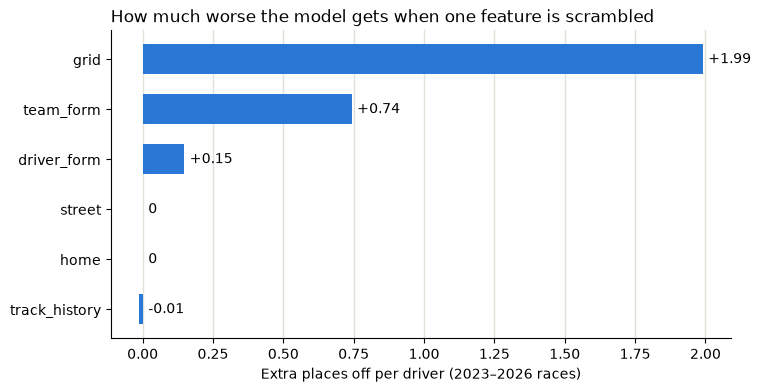

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance.index, importance.values, height=0.6, color="#2a78d6")

# Write the value at the end of each bar (anything smaller than 0.005 shows as 0)
for i, value in enumerate(importance.values):
    label = f"{value:+.2f}" if abs(value) >= 0.005 else "0"
    ax.text(max(value, 0) + 0.02, i, label, va="center")

ax.invert_yaxis()
ax.set_title("How much worse the model gets when one feature is scrambled", loc="left")
ax.set_xlabel("Extra places off per driver (2023–2026 races)")
ax.grid(axis="x", color="#e1e0d9", linewidth=1)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [24]:
# Test the idea: drop street, home and track_history, retrain on the same races, and score again
simple_features = ["grid", "team_form", "driver_form"]
simple_model = LinearRegression()
simple_model.fit(train_finishers[simple_features], train_finishers["position"])
test["predicted_simple"] = simple_model.predict(test[simple_features])

results["Model, 3 features"] = score(test, "predicted_simple")
results.round(2)

,Model,Finish = grid,"Model, 3 features"
Places off (lower is better),2.28,2.49,2.26
Link (higher is better),0.80,0.76,0.80
"Podium picks, out of 3",1.99,2.01,2.04
Share of races where the pick won,0.63,0.61,0.62


In [25]:
# Where does the model help, and where doesn't it? Average places off, split by grid position
# (uses the finishers table from the luck test, which has model_off and grid_off for every finisher)
finishers["grid_group"] = pd.cut(finishers["grid"], bins=[0, 3, 6, 10, 15, 30],
                                 labels=["1-3", "4-6", "7-10", "11-15", "16+"])
by_grid = finishers.groupby("grid_group", observed=True)[["model_off", "grid_off"]].mean()
by_grid["gain"] = by_grid["grid_off"] - by_grid["model_off"]
by_grid["drivers"] = finishers.groupby("grid_group", observed=True).size()
by_grid.round(2)

,model_off,grid_off,gain,drivers
grid_group,,,,
1-3,1.70,1.75,0.05,251
4-6,1.98,2.00,0.02,249
7-10,2.35,2.56,0.21,315
11-15,2.61,2.71,0.11,385
16+,2.48,3.02,0.54,382


Scrambling one feature at a time inside each race shows what the model relies on. Grid position matters most: scrambling it adds about 2 places of error per driver. Team form comes second (+0.74) and driver form adds a little (+0.15). Street track, home race and track history add nothing (0 to −0.01), which fits Part 2. A street track is the same for every driver in a race, so it can't change the order (and 2.1 found Monaco wasn't special anyway). The home boost shows up in qualifying (2.3), which the grid already includes. Track specialists are too small and noisy to help (2.4). A model with only grid, team form and driver form does just as well (2.26 places off against 2.28, and 2.04 podium picks against 1.99), so the simpler model is the one to keep. The model's gains come from the back of the grid: for drivers starting 16th or lower it is about half a place closer than the grid (2.48 against 3.02), but for the top 6 it is no better. That's where it fails. The front of the race, where podiums and wins are decided, is already well predicted by the grid, and the model can't improve on it.